# SNO 2026
# Processando dados de CTD

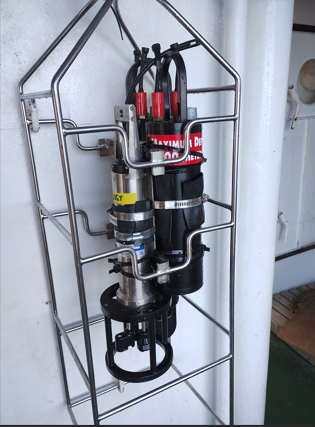
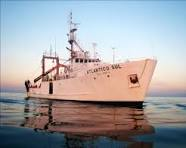

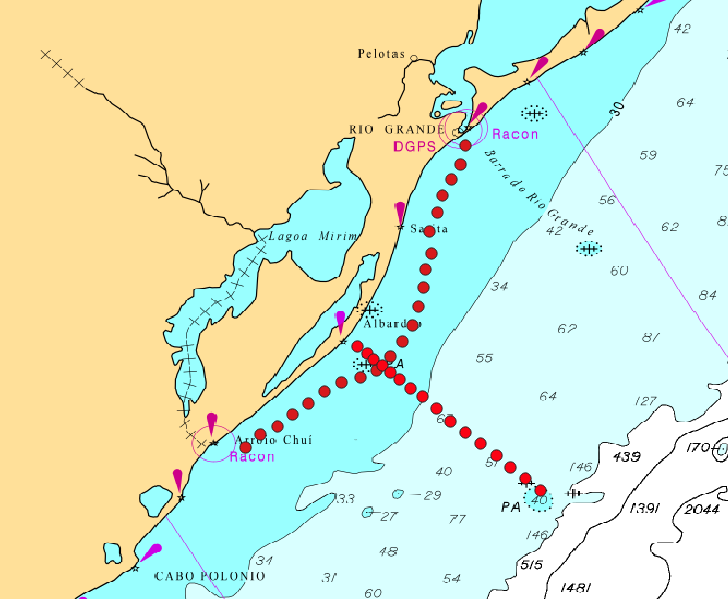

# 1) Acessar os dados (carregar!) 
- Arquivo formato ASCII - American Standard Code for Information Interchange
- Explore o conteúdo utilizando um editor de text (notepad ou qualquer outro)  
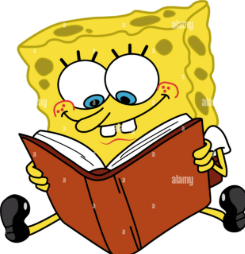

In [43]:
arquivo = '202311091101_ASTD102-ALC-R02_0046_110156.csv'

with open(arquivo) as io:
    linhas = io.readlines()

- Explorando os dados e verificando onde está o cabeçalho e onde começam os dados

In [44]:
for i, linha in enumerate(linhas[:70]):
    print(i, linha)

0 ï»¿// JOGOS

1 // Version 1.01

2 // File Date:2023/11/09 11:14:38

3 // (C) 2020 JFE Advantech Co., Ltd.

4 

5 [Format]

6 FormatVersion=1.00

7 DataFormat=1

8 Delimiter=0

9 Model=JOGOS

10 

11 [Head]

12 SondeName=ASTD102-ALC-R02

13 SondeNo=0046

14 SensorType=D0D1T1C1C2K0U3O0TOB0

15 SensorType2=06070303000202020302

16 Channel=10

17 Comment=

18 MeasMode=0

19 

20 PreHeat=5000

21 Interval=100

22 SampleCnt=5510

23 

24 StartTime=2023/11/09 11:02:01

25 EndTime=2023/11/09 11:11:11

26 

27 DepAdjRho=1.0197

28 

29 ECA=0

30 ECB=1

31 ECDeg=25

32 ECCoef=0.022

33 

34 CHLA=0

35 CHLB=1

36 

37 PC_SWA=0

38 PC_SWB=0

39 PC_SWC=0

40 PC_SWD=0

41 

42 DepthZero=0

43 StartDepthA=0

44 StartDepthB=0

45 

46 FilmNo=200634BA

47 

48 CondDepB=0

49 DepM=0

50 

51 FormulaDOM=0

52 ExplanationDOM=Weiss (1970)

53 

54 CoefDate=2020/12/14

55 

56 Ch1=-3.255494e-01,+1.035111e-04,+0.000000e+00,+0.000000e+00,+0.000000e+00,+0.000000e+00,+0.000000e+00,+0.000000e+00,

57 Ch2=0.000

- Sabendo que o cabeçalho é a linha com índice 68

In [45]:
cabecalho = linhas[68]
print(cabecalho)

Measurement Date/Time,Press. [dbar],Temp. [â„ƒ],Salinity,Cond. [mS/cm],EC [Î¼S/cm],Density [kg/m3],SigmaT,Chl-Flu. [ppb],Chl-a [ppb],Turb. [FTU],DO [%],DO [mg/l],DO [Î¼mol/l],Batt. [V]



- quebrando a string com a vírgula, e mostrando...

In [46]:
cabecalho = cabecalho.split(',')
for i, c in enumerate(cabecalho):
    print(i, c)

0 Measurement Date/Time
1 Press. [dbar]
2 Temp. [â„ƒ]
3 Salinity
4 Cond. [mS/cm]
5 EC [Î¼S/cm]
6 Density [kg/m3]
7 SigmaT
8 Chl-Flu. [ppb]
9 Chl-a [ppb]
10 Turb. [FTU]
11 DO [%]
12 DO [mg/l]
13 DO [Î¼mol/l]
14 Batt. [V]



- prototipando o processamento dos dados

In [47]:
dado_1 = linhas[69]
print(dado_1)

2023/11/09 11:02:01,-0.860,16.905,0.033,0.053,63.887,998.814,-1.182,0.00,0.00,3.68,100.32,9.968,311.521,8.43,



In [48]:
dado_1 = dado_1.split(',')
print(dado_1)

['2023/11/09 11:02:01', '-0.860', '16.905', '0.033', '0.053', '63.887', '998.814', '-1.182', '0.00', '0.00', '3.68', '100.32', '9.968', '311.521', '8.43', '\n']


- cada linha é uma string
- com o 'split', converte em uma lista de strings
- o tempo tem que ser tratado separado, mas os demais campos são 'floats'
- Agora, pegando cada linha de dados, quebrando a string, convertendo em 'float' e armazenando em outra lista

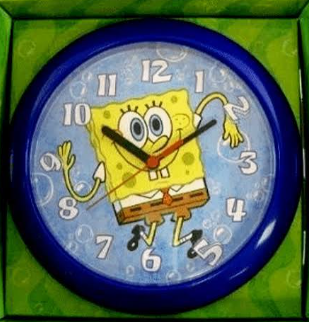
- O tempo no Python deve ser tratado com um objeto 'datetime'... para isso podemos usar o pacote 'dateutils.parser' que converte strings de tempo em objeto datetime!

In [49]:
# importanto pacote!
from dateutil.parser import parse

In [50]:
print(dado_1[0], type(dado_1[0]))
print(parse(dado_1[0]), type(parse(dado_1[0])))

2023/11/09 11:02:01 <class 'str'>
2023-11-09 11:02:01 <class 'datetime.datetime'>


In [51]:
# cria uma lista vazia
dados = []
tempo = []
for linha in linhas[69:-1]:
    liq = linha.split(',')

    #'guarda' o tempo na lista vazia criada
    tempo.append(parse(liq[0]))
    # converte as strings em floats... isto é um procedimento 'list compreension'
    floats = [float(x) for x in liq[1:-1]]
    # guarda os dados
    dados.append(floats)

In [52]:
print(type(tempo), len(tempo))
print(type(dados), len(dados))
print(tempo[0])
print(dados[0])

<class 'list'> 5510
<class 'list'> 5510
2023-11-09 11:02:01
[-0.86, 16.905, 0.033, 0.053, 63.887, 998.814, -1.182, 0.0, 0.0, 3.68, 100.32, 9.968, 311.521, 8.43]


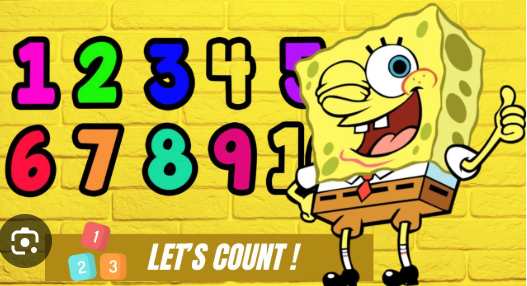

## Numeros --> Numpy
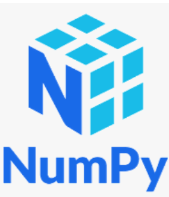

In [53]:
import numpy as np

In [54]:
dados = np.vstack(dados)

print(type(dados), len(dados), dados.shape)
print(dados[0])

<class 'numpy.ndarray'> 5510 (5510, 14)
[-8.60000e-01  1.69050e+01  3.30000e-02  5.30000e-02  6.38870e+01
  9.98814e+02 -1.18200e+00  0.00000e+00  0.00000e+00  3.68000e+00
  1.00320e+02  9.96800e+00  3.11521e+02  8.43000e+00]


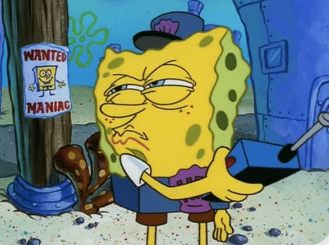
- 'listas' são objetos do Python nativo... são sequência ordenadas, porém mutáveis, de objetos
- 'arrays' são objetos do Numpy. São estruturas de dados homogêneas (mesmo tipo de objetos), e multidimensionais (listas não tem dimensões!)

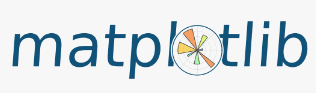
- Para fazer gráficos --> Matplotbib

In [55]:
import matplotlib.pyplot as plt

- Vamos inicialmente explorar o tempo e a pressão... 

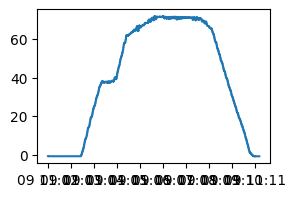

In [59]:
plt.figure(figsize=(3,2))
plt.plot(tempo, dados[:,0])

Text(0, 0.5, 'Profundidade (m)')

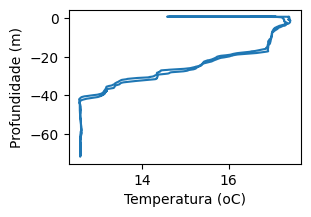

In [62]:
plt.figure(figsize=(3,2))
plt.plot(dados[:,1], -dados[:,0])
plt.xlabel('Temperatura (oC)')
plt.ylabel('Profundidade (m)')